# Day 3: Attention

On day 2 the vector of `sick` changed with its sentence. The mechanism behind that is self-attention: in every block each token decides how much to take from every other token. These weights can be read out of the model and drawn.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch

from itg_transformers.attention import (
    head_patterns,
    layer_summary,
    plot_heads,
    visualize_attention,
    word_attention,
)
from itg_transformers.config import FIGURES_DIR
from itg_transformers.data import load_split
from itg_transformers.embeddings import load_model
from itg_transformers.tokenization import load_tokenizer, tokenize_texts

tokenizer = load_tokenizer()

## 1. Loading the model with attention output

In [2]:
model = load_model(output_attentions=True)

print("Returns attentions:", model.config.output_attentions)
print("Attention implementation:", model.config._attn_implementation)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Returns attentions: True
Attention implementation: eager


By default transformers computes attention with a fused PyTorch kernel (`sdpa`), which is fast but never materialises the weights. Asking for `output_attentions=True` switches the model to the plain (`eager`) implementation that keeps them. That is why `load_model` leaves the flag off unless we need the weights.

In [3]:
text = "The amazing movie won many awards"
tokens = tokenize_texts([text], tokenizer).to(model.device)
token_list = tokens.tokens(0)
print(token_list)

['[CLS]', 'the', 'amazing', 'movie', 'won', 'many', 'awards', '[SEP]']


## 2. Attention weights

In [4]:
with torch.no_grad():
    outputs = model(**tokens, output_hidden_states=True)

print(type(outputs.attentions).__name__)
print(f"Number of layers: {len(outputs.attentions)}")
print(f"Attention shape of layer 0: {outputs.attentions[0].shape}")

tuple
Number of layers: 6
Attention shape of layer 0: torch.Size([1, 12, 8, 8])


A tuple with one tensor per block, each of shape `[batch_size, num_heads, seq_len, seq_len]`: 1 text, 12 heads, and for each head an 8 × 8 table, every token against every token.

In [5]:
attention = outputs.attentions[0]  # first layer
print(f"Attention shape: {attention.shape}")

attn_single = attention[0, 0]  # first text of the batch, first head
print(f"Single head shape: {attn_single.shape}")

Attention shape: torch.Size([1, 12, 8, 8])
Single head shape: torch.Size([8, 8])


The same table with token labels. Row = the token that is being updated (*query*), column = the token it takes information from (*key*):

In [6]:
pd.DataFrame(
    attn_single.cpu().numpy(), index=token_list, columns=token_list
).round(2)

,[CLS],the,amazing,movie,won,many,awards,[SEP]
[CLS],0.07,0.14,0.07,0.09,0.13,0.08,0.09,0.33
the,0.36,0.10,0.07,0.06,0.14,0.08,0.08,0.12
amazing,0.32,0.02,0.08,0.08,0.12,0.03,0.11,0.25
movie,0.20,0.03,0.11,0.09,0.12,0.05,0.20,0.21
won,0.44,0.05,0.10,0.13,0.05,0.05,0.08,0.09
many,0.45,0.04,0.08,0.04,0.20,0.04,0.08,0.08
awards,0.45,0.03,0.10,0.15,0.08,0.03,0.06,0.11
[SEP],0.21,0.15,0.03,0.04,0.08,0.15,0.05,0.28


In [7]:
print(f"Row sums: {attn_single.sum(dim=-1).cpu().numpy().round(4)}")

Row sums: [1. 1. 1. 1. 1. 1. 1. 1.]


Every row sums to 1: it is a distribution of one token's attention over all tokens. The new vector of a token is the mix of the other tokens' vectors with exactly these proportions.

### Where the numbers come from

Every token vector `x` is turned into three vectors by the linear layers we saw in `print(model)`:

- query `q = q_lin(x)`: what this token is looking for;
- key `k = k_lin(x)`: what this token offers to others;
- value `v = v_lin(x)`: what it passes on if chosen.

The 768 numbers are split into 12 heads of 64. For one head, the weight of token *j* in the row of token *i* is

$$\text{softmax}_j\left(\frac{q_i \cdot k_j}{\sqrt{64}}\right)$$

A large dot product means the query matches the key. Division by √64 keeps the numbers in a range where softmax is not saturated. Recomputing head 0 of layer 0 by hand from the input of the first block:

In [8]:
q_lin = model.get_submodule("transformer.layer.0.attention.q_lin")
k_lin = model.get_submodule("transformer.layer.0.attention.k_lin")
x = outputs.hidden_states[0][0]  # input of block 1: [seq_len, 768]
head_size = model.config.dim // model.config.n_heads

with torch.no_grad():
    q = q_lin(x)[:, :head_size]  # head 0 = first 64 numbers
    k = k_lin(x)[:, :head_size]
    scores = q @ k.T / head_size**0.5
    manual = torch.softmax(scores, dim=-1)

print(f"Head size: {head_size}")
print(f"Matches the model: {torch.allclose(manual, attn_single, atol=1e-5)}")

Head size: 64
Matches the model: True


### What `attention_mask` does here

Before the softmax, positions with mask 0 get a score of minus infinity, so their weight becomes exactly 0. A short text padded in a batch with a long one:

In [9]:
padded = tokenize_texts([text, text + " and a lot of praise"], tokenizer)
with torch.no_grad():
    padded_attention = model(**padded.to(model.device)).attentions[0]

short_row = padded_attention[0, 0, 0].cpu().numpy()
padded_tokens = padded.tokens(0)
pd.Series(short_row, index=padded_tokens, name="[CLS] attends to").round(3)

[CLS]      0.074
the        0.138
amazing    0.074
movie      0.095
won        0.125
many       0.082
awards     0.088
[SEP]      0.325
[PAD]      0.000
[PAD]      0.000
[PAD]      0.000
[PAD]      0.000
[PAD]      0.000
Name: [CLS] attends to, dtype: float32

The `[PAD]` columns get exactly 0, and the remaining weights are the same as without padding. This is how the mask keeps batching from changing the result, as tested on day 2.

## 3. Visualizing attention

`visualize_attention` draws one head of one layer as a heatmap: rows are queries, columns are keys, brighter means more attention. Every plot is also saved to `figures/`.

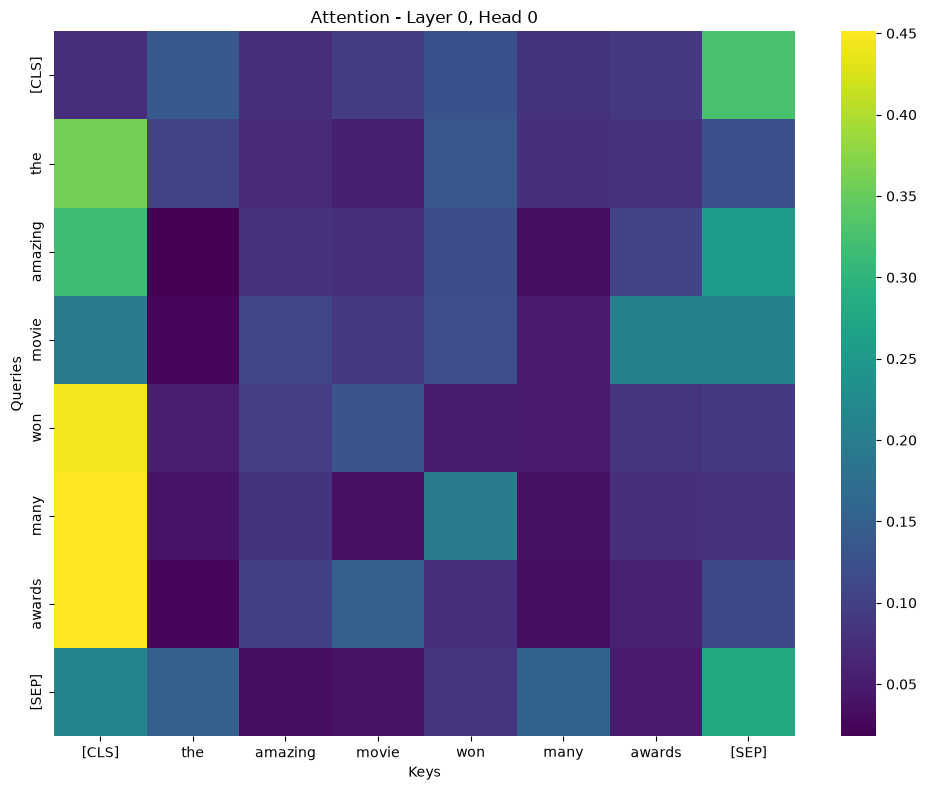

In [10]:
visualize_attention(tokens, outputs.attentions, layer=0, head=0)

This is the table from section 2 as a picture: the bright `[CLS]` column on the left and `[SEP]` column on the right are the tokens that most rows look at.

In [11]:
for path in sorted(FIGURES_DIR.glob("attention_*.png")):
    print(path.relative_to(FIGURES_DIR.parent))

figures/attention_layer0_head0.png
figures/attention_layer0_head2.png
figures/attention_layer1_head9.png
figures/attention_layer3_head0.png
figures/attention_layer5_head0.png


## 4. Attention across layers

The same head 0 in the first, a middle and the last layer:

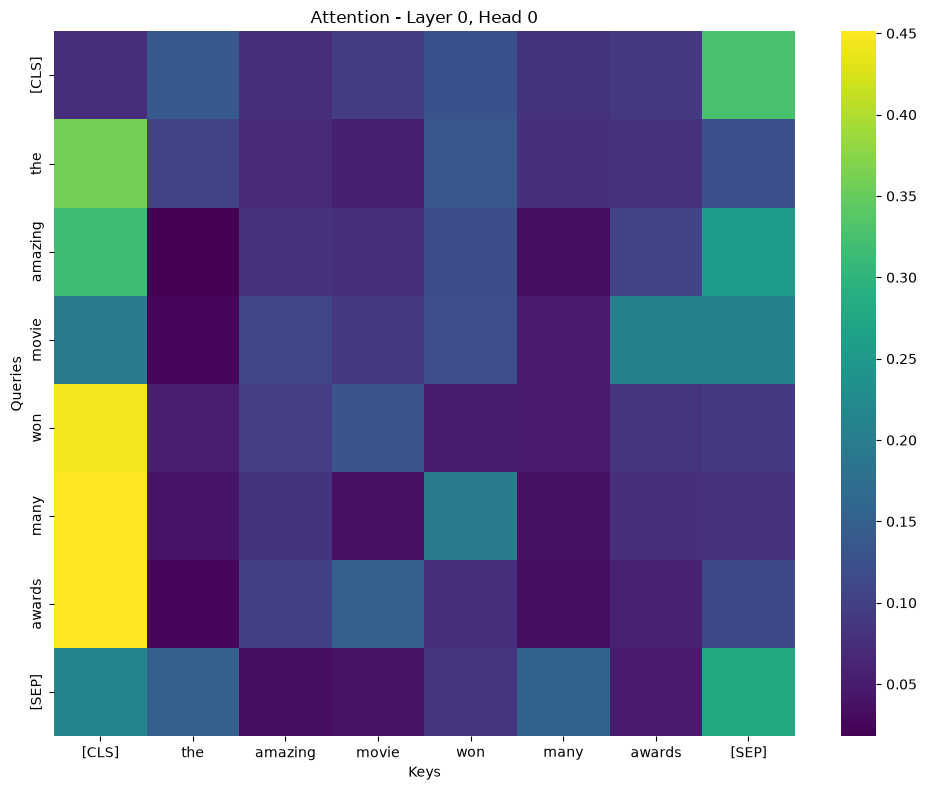

In [12]:
visualize_attention(tokens, outputs.attentions, layer=0, head=0)

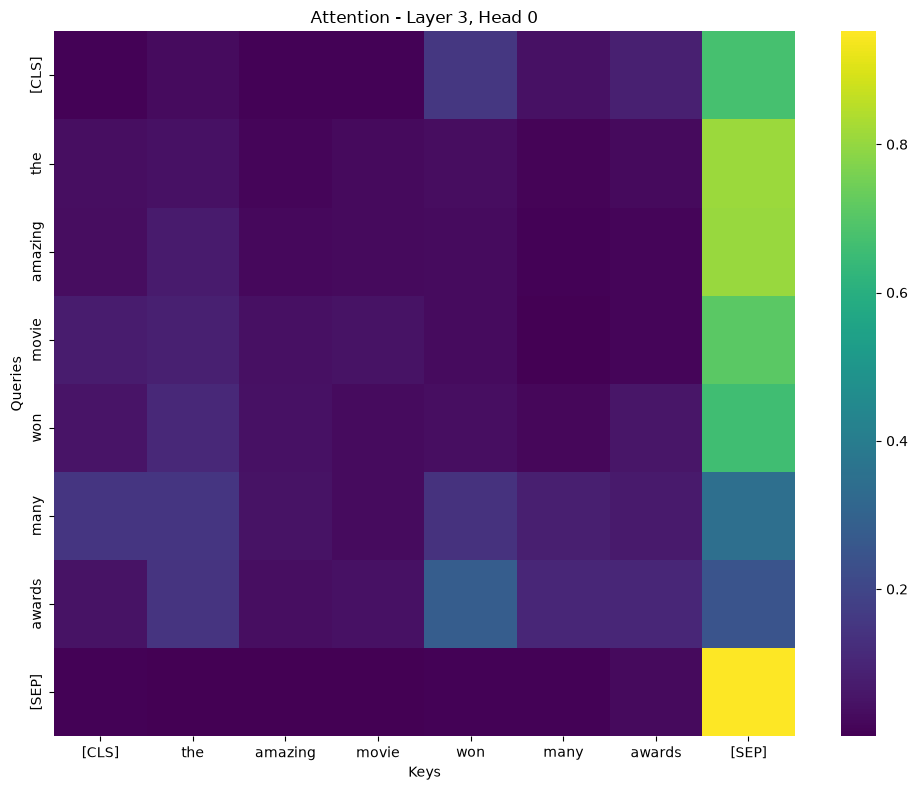

In [13]:
visualize_attention(tokens, outputs.attentions, layer=3, head=0)

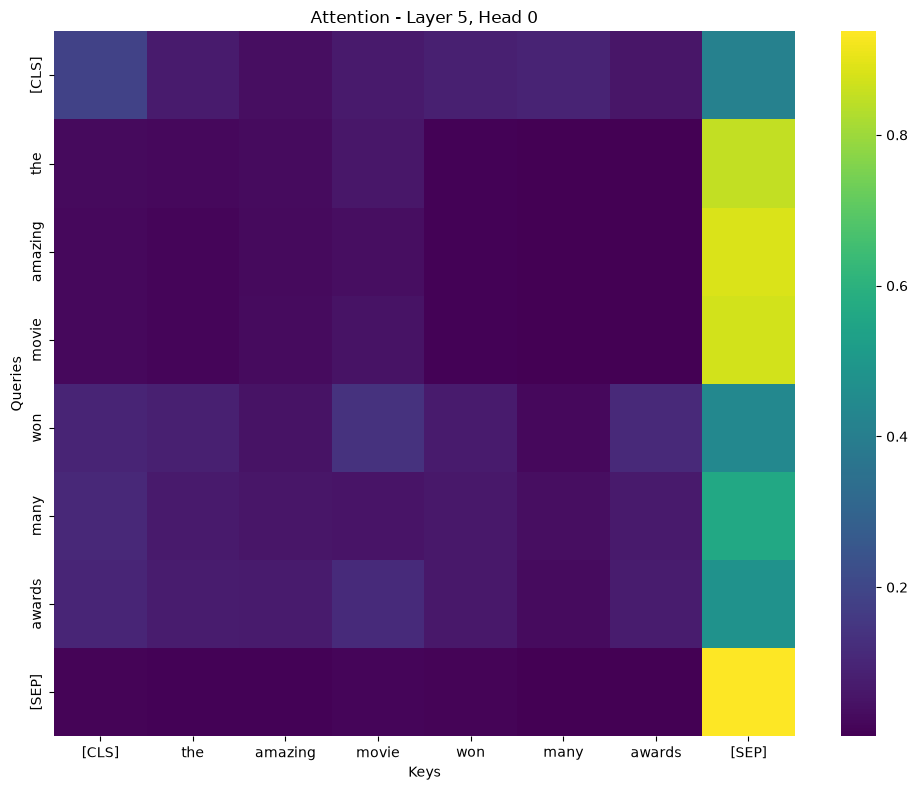

In [14]:
visualize_attention(tokens, outputs.attentions, layer=5, head=0)

Three pictures of one head are anecdotes. To check the claim that attention gets more focused in later layers, `layer_summary` averages over all 12 heads and all real tokens:

- `entropy`: how spread out a row is (0 = all weight on one token, log(n) = spread evenly over n tokens);
- `max_weight`: the largest weight in a row;
- `to_cls`, `to_sep`: weight that lands on the special tokens.

In [15]:
layer_summary(outputs.attentions, tokens["attention_mask"]).round(3)

,entropy,max_weight,to_cls,to_sep
layer,,,,
0,1.291,0.545,0.323,0.133
1,1.030,0.651,0.442,0.180
2,1.040,0.655,0.087,0.618
3,0.845,0.743,0.036,0.708
4,1.052,0.684,0.043,0.683
5,1.063,0.689,0.046,0.682


One sentence is still a small sample. The same over 256 train tweets:

In [16]:
sample = load_split("train")["text"].sample(256, random_state=0).tolist()
sample_tokens = tokenize_texts(sample, tokenizer).to(model.device)
with torch.no_grad():
    sample_attentions = model(**sample_tokens).attentions

summary = layer_summary(sample_attentions, sample_tokens["attention_mask"])
summary.round(3)

,entropy,max_weight,to_cls,to_sep
layer,,,,
0,2.219,0.378,0.177,0.046
1,1.765,0.511,0.276,0.093
2,1.743,0.511,0.052,0.436
3,1.301,0.624,0.019,0.538
4,1.785,0.538,0.022,0.523
5,1.915,0.473,0.025,0.415


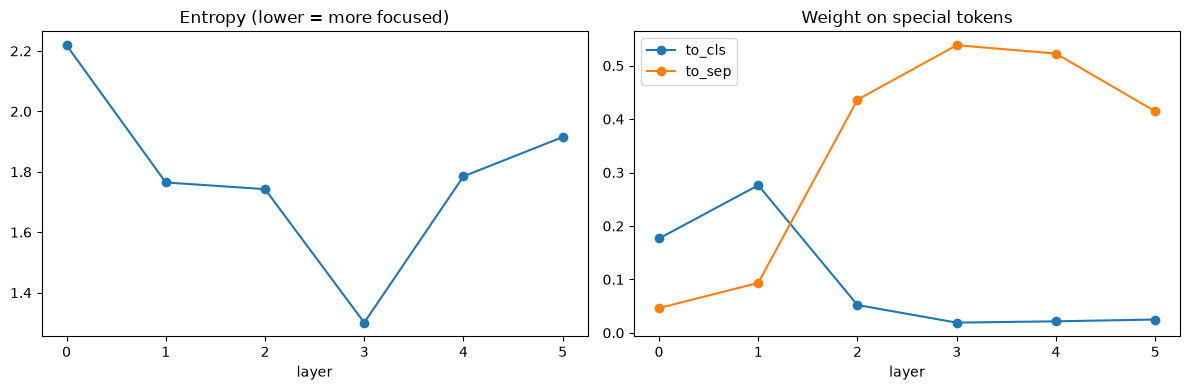

In [17]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
summary["entropy"].plot(
    ax=left, marker="o", title="Entropy (lower = more focused)"
)
summary[["to_cls", "to_sep"]].plot(
    ax=right, marker="o", title="Weight on special tokens"
)
for ax in (left, right):
    ax.set_xlabel("layer")
plt.tight_layout()
plt.show()

Attention does get more focused than in layer 0: entropy drops and the largest weight in a row grows. But the claim needs two corrections:

1. The most focused layer is the middle one (layer 3), not the last. Layers 4-5 spread out again, on the tweets more than on our sentence.
2. Most of that focus goes to `[SEP]`: from layer 2 on, about half of all attention lands there, while in layers 0-1 it parks on `[CLS]`. This is the "no-op" pattern from section 3 moving from one special token to the other, not attention to meaningful words.

The interesting links are the weights that remain: in layer 3, head 0, `awards` reads mostly from `won` (its verb) instead of `[SEP]`.

## 5. Attention of different heads

DistilBERT has 12 heads per layer (the task text says 8, the config says `n_heads = 12`). Instead of 12 separate figures, all heads of layer 0 in one grid with a shared color scale:

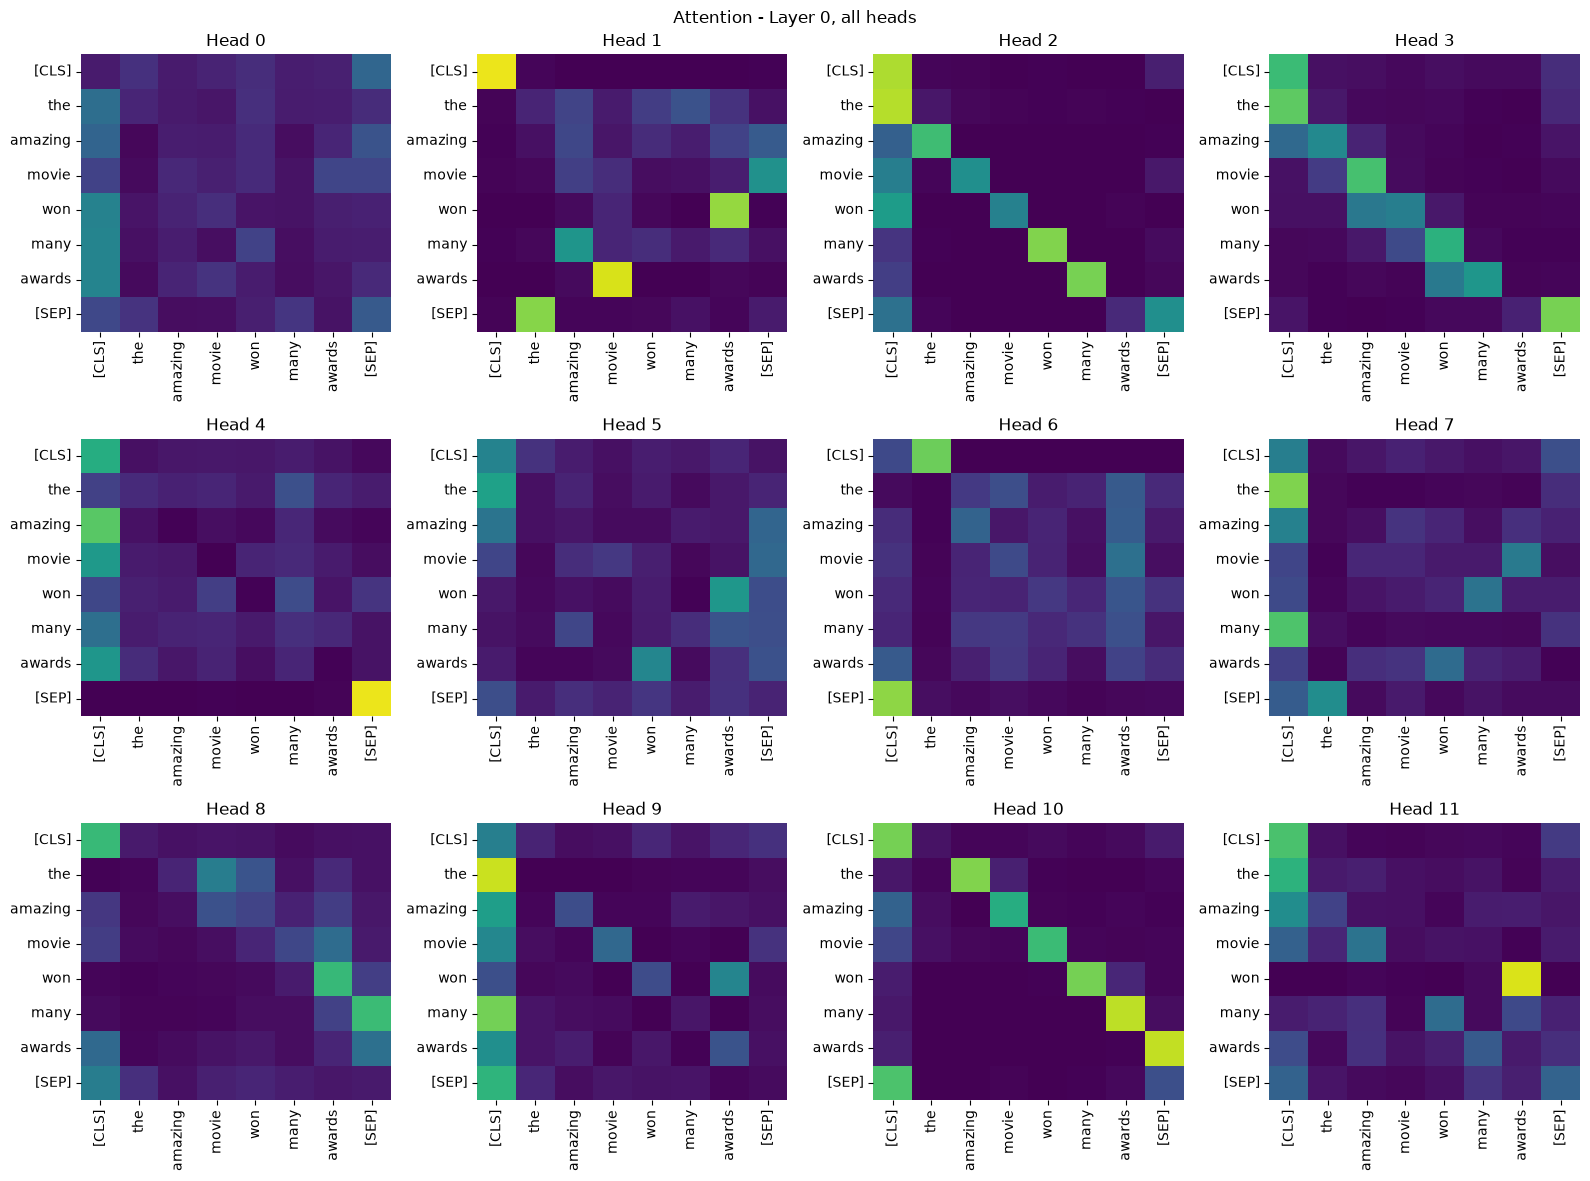

In [18]:
plot_heads(tokens, outputs.attentions, layer=0)

The heads clearly differ: some spread their attention, some look at one neighbour, some at the special tokens. `head_patterns` measures, for every head of every layer over the 256 tweets, how much weight goes to the previous token, the token itself, the next token, `[CLS]` and `[SEP]`:

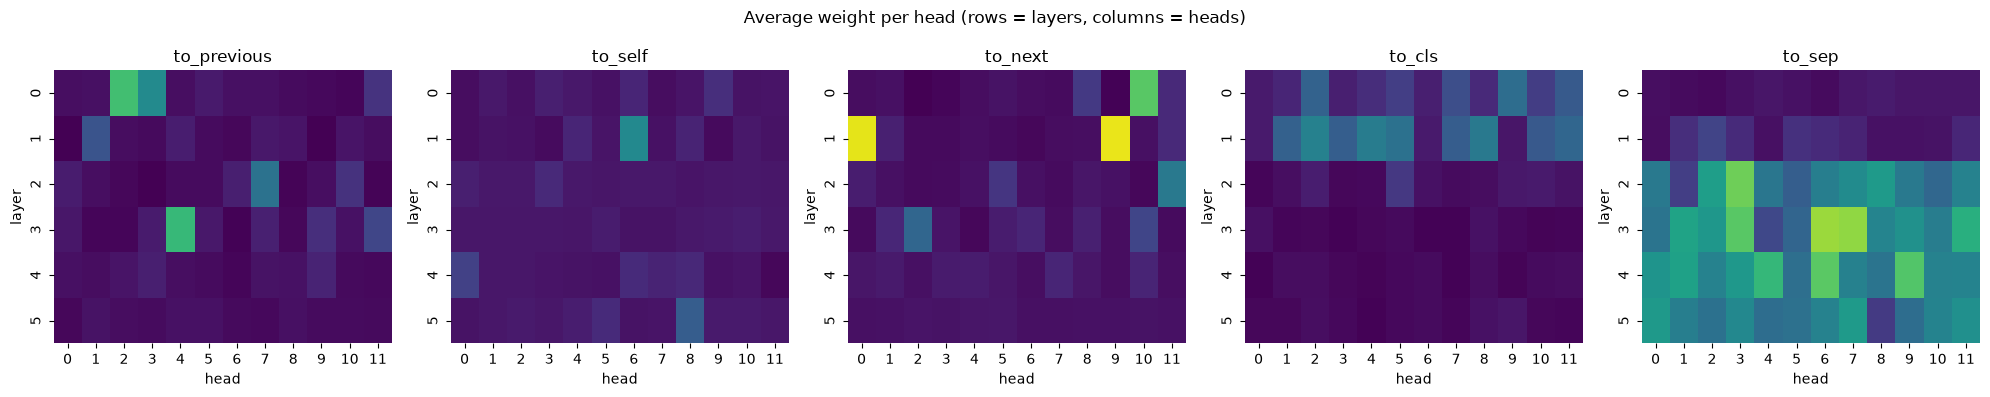

In [19]:
patterns = head_patterns(sample_attentions, sample_tokens["attention_mask"])

fig, axes = plt.subplots(1, len(patterns.columns), figsize=(20, 4))
for ax, pattern in zip(axes, patterns.columns, strict=True):
    sns.heatmap(
        patterns[pattern].unstack(),
        vmin=0,
        vmax=1,
        cmap="viridis",
        cbar=False,
        annot=False,
        ax=ax,
    )
    ax.set_title(pattern)
fig.suptitle("Average weight per head (rows = layers, columns = heads)")
fig.tight_layout()
plt.show()

The most specialised head for every pattern:

In [20]:
best = pd.DataFrame(
    {
        "layer, head": patterns.idxmax(),
        "average weight": patterns.max(),
    }
)
best.round(2)

,"layer, head",average weight
to_previous,"(0, 2)",0.70
to_self,"(1, 6)",0.47
to_next,"(1, 9)",0.96
to_cls,"(1, 2)",0.44
to_sep,"(3, 6)",0.85


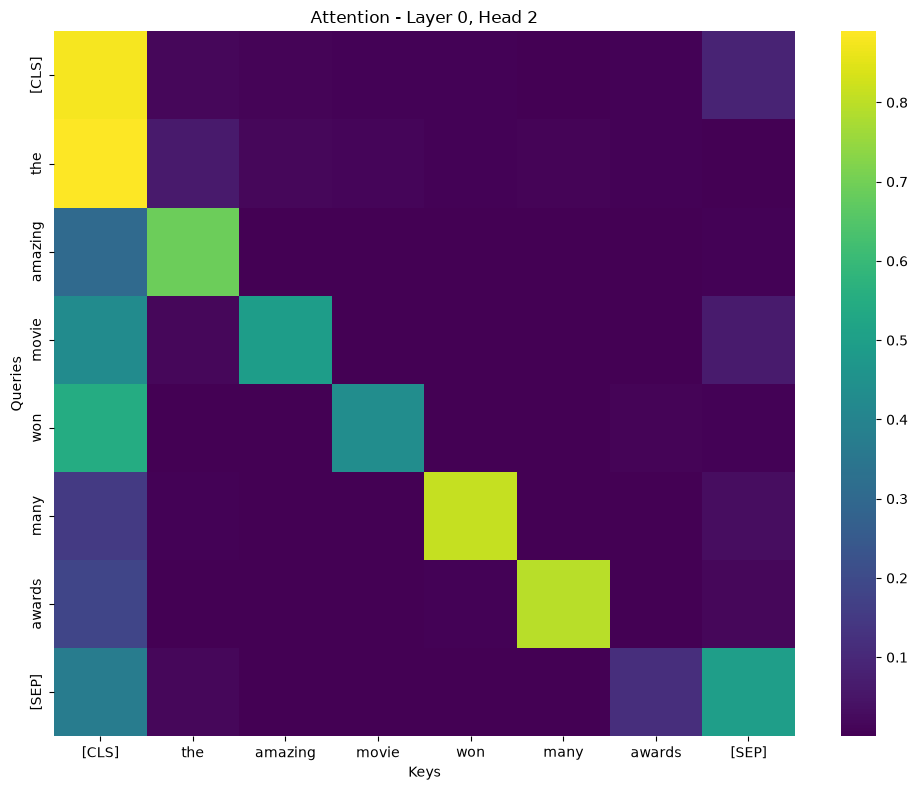

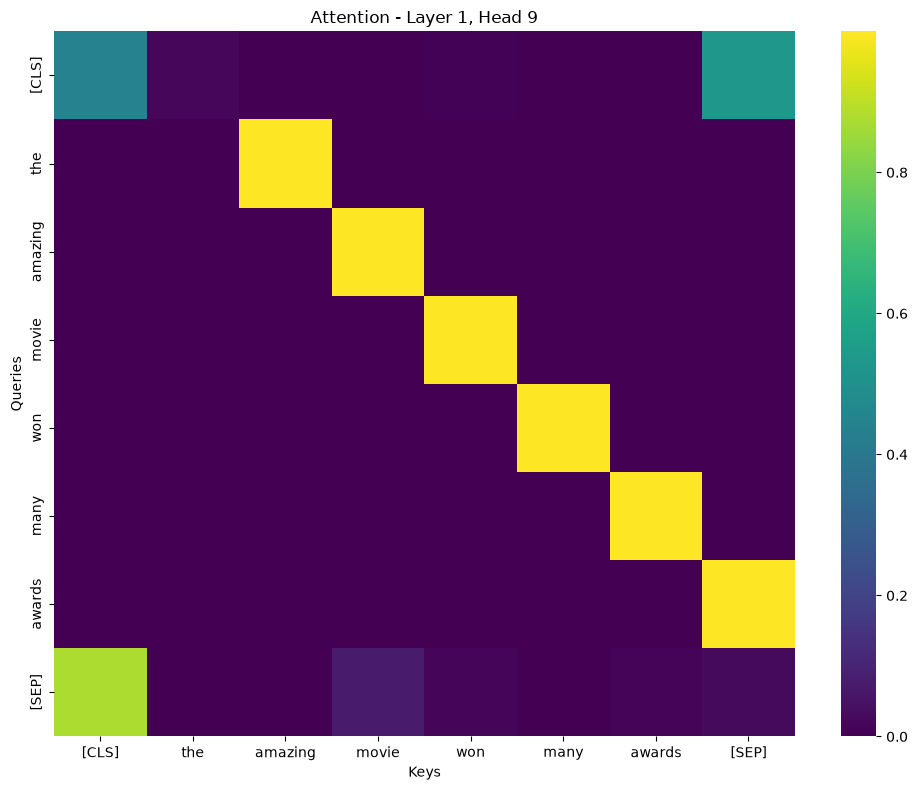

In [21]:
for layer, head in best.loc[["to_previous", "to_next"], "layer, head"]:
    visualize_attention(tokens, outputs.attentions, layer=layer, head=head)

Different heads do focus on different relations, and many of them are about position rather than meaning:

- **previous-token heads**: layer 0 heads 2 and 3 (a bright diagonal just below the main one in the grid);
- **next-token heads**: layer 0 head 10, and layer 1 heads 0 and 9, which put about 96% of their weight on the next token;
- **`[CLS]` heads**: spread over layer 1;
- **`[SEP]` heads**: almost every head of layers 2-5.

Positional heads sit in the first two layers: they let every token pick up its neighbours, so later layers work with tokens that already know their local context. Heads that link words by meaning are rarer and less regular, for example layer 0 head 1, where `won` looks at `awards` and `awards` at `movie`.

## 6. Attention to a sentiment word

A text with a clearly negative word. The plots get the prefix `terrible`, so they do not overwrite the ones of the first text.

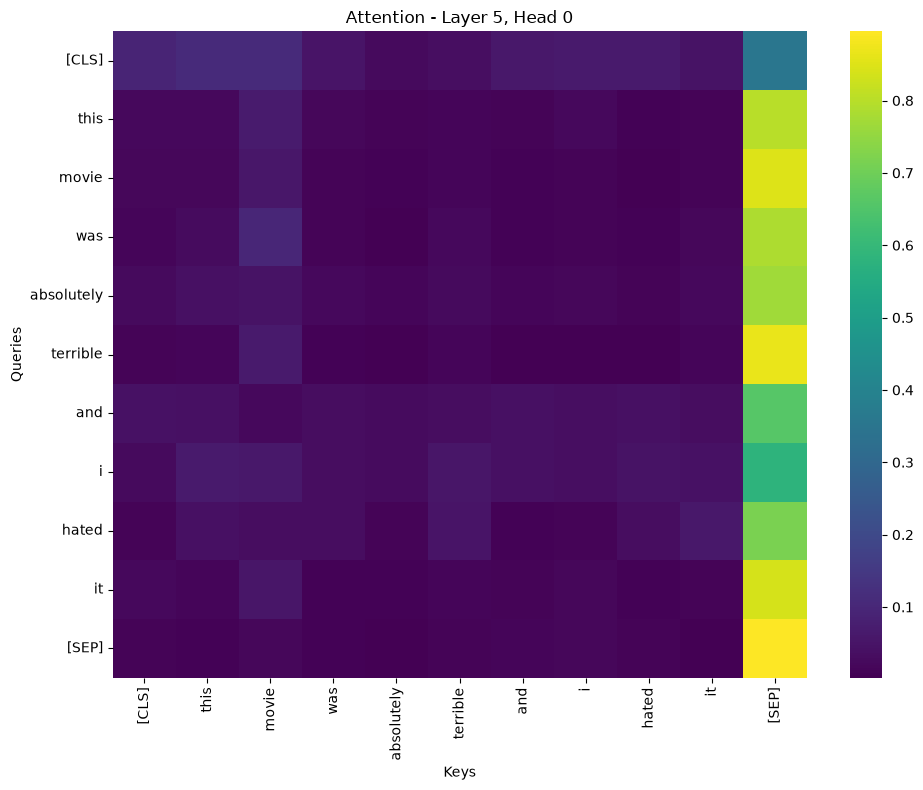

In [22]:
text = "This movie was absolutely terrible and I hated it"
tokens = tokenize_texts([text], tokenizer).to(model.device)

with torch.no_grad():
    outputs = model(**tokens)

visualize_attention(
    tokens, outputs.attentions, layer=5, head=0, name="terrible"
)

In layer 5, head 0, the row of `terrible` is almost entirely `[SEP]`. One head is again a weak witness, so `word_attention` averages the row of `terrible` over all 12 heads, layer by layer:

In [23]:
reads = word_attention(tokens, outputs.attentions, "terrible")
reads.round(2)

,[CLS],this,movie,was,absolutely,terrible,and,i,hated,it,[SEP]
layer,,,,,,,,,,,
0,0.22,0.03,0.04,0.05,0.22,0.06,0.10,0.06,0.07,0.03,0.10
1,0.36,0.03,0.03,0.07,0.03,0.10,0.21,0.02,0.04,0.03,0.08
2,0.05,0.02,0.04,0.03,0.04,0.03,0.04,0.02,0.03,0.02,0.68
3,0.02,0.03,0.04,0.07,0.06,0.03,0.03,0.01,0.01,0.02,0.68
4,0.02,0.05,0.07,0.04,0.03,0.07,0.02,0.01,0.02,0.04,0.62
5,0.02,0.04,0.04,0.04,0.03,0.07,0.02,0.02,0.03,0.03,0.65


From layer 2 on about two thirds go to `[SEP]`. Dropping the special tokens and `terrible` itself, and rescaling the rest to sum to 1, shows which *words* it reads from:

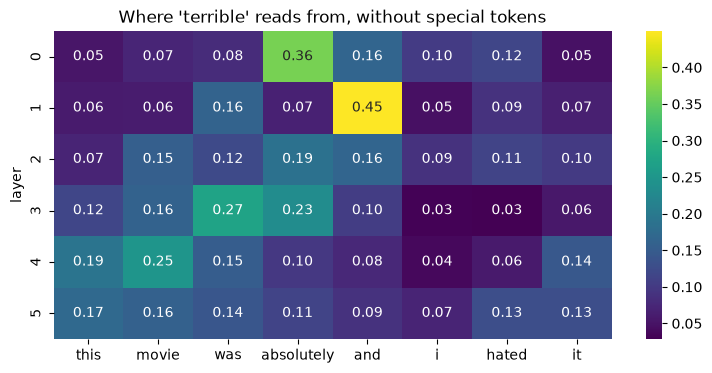

In [24]:
words = reads.drop(columns=["[CLS]", "[SEP]", "terrible"])
words = words.div(words.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(words, annot=True, fmt=".2f", cmap="viridis", ax=ax)
ax.set_title("Where 'terrible' reads from, without special tokens")
plt.show()

And the other direction: which tokens read from `terrible`.

In [25]:
read_by = word_attention(
    tokens, outputs.attentions, "terrible", reads_from=False
)
read_by.round(2)

,[CLS],this,movie,was,absolutely,terrible,and,i,hated,it,[SEP]
layer,,,,,,,,,,,
0,0.04,0.07,0.06,0.10,0.18,0.06,0.17,0.10,0.08,0.08,0.02
1,0.02,0.02,0.02,0.11,0.19,0.10,0.03,0.02,0.04,0.02,0.01
2,0.02,0.03,0.04,0.11,0.05,0.03,0.04,0.03,0.03,0.03,0.00
3,0.02,0.04,0.04,0.11,0.06,0.03,0.05,0.01,0.01,0.02,0.00
4,0.03,0.05,0.03,0.10,0.08,0.07,0.03,0.02,0.03,0.04,0.02
5,0.06,0.03,0.03,0.05,0.04,0.07,0.02,0.03,0.03,0.04,0.01


What `terrible` attends to, layer by layer (words only):

- layers 0-1: its neighbours, `absolutely` (previous token, 36%) and `and` (next token, 45%), the positional heads of section 5;
- layer 3: `was` and `absolutely`, the predicate it belongs to ("was absolutely terrible");
- layer 4: `movie` (25%), the thing being called terrible;
- layer 5: almost flat.

The other sentiment word, `hated`, gets little attention in any layer (at most 13%). The pre-trained model links `terrible` to its syntax (modifier, verb, subject), not to other words of the same sentiment; it was never trained for sentiment (see day 2). And all these word links share the remaining third of the attention: in layers 2-5 about two thirds still go to `[SEP]`.

## Summary

1. **Attention weights** are, for every token, a distribution over all tokens (rows sum to 1), computed from queries and keys as `softmax(q·k / √64)`. The new vector of a token mixes the value vectors of the others in these proportions. Padding gets exactly 0.
2. **Weight is not influence**: special tokens get a lot of weight but pass short value vectors (section 3).
3. **Across layers**: attention gets more focused than in layer 0, with the peak in the middle layer, and most of the focus lands on `[SEP]` (from layer 2 on) or `[CLS]` (layers 0-1). This is a no-op pattern, not attention to important words.
4. **Across heads**: the first layers have positional heads (previous / next token, up to 96% of the weight); most heads of layers 2-5 park on `[SEP]`; meaningful word links are rarer.
5. **Sentiment word**: `terrible` follows its syntax (`absolutely`, `was`, `movie`) rather than the other sentiment word `hated`.